<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/biasvar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bias, varianza e regolarizzazione: un esperimento con ridge regression

Questo notebook illustra due aspetti della **regolarizzazione** discussa nelle note:

1. l'effetto del coefficiente di regolarizzazione sul compromesso tra **bias** e **varianza**, osservato addestrando lo stesso modello su molti training set diversi (è l'esperimento dell'esempio analogo delle note, e della figura con le $100$ curve per tre valori di $\ln\lambda$);
2. l'andamento dei **coefficienti** appresi dalla ridge regression al variare del coefficiente di regolarizzazione (il cosiddetto *regularization path*).

## Richiami

Il modello è lineare in un insieme di funzioni base gaussiane (radiali),
$$h(x;\mathbf{w})=\sum_{j=1}^m w_j\,\phi_j(x),\qquad \phi_j(x)=\exp\Bigl(-\frac{(x-\mu_j)^2}{2s^2}\Bigr),$$
e i coefficienti sono stimati con la **ridge regression**, cioè minimizzando
$$E(\mathbf{w})=\frac12\sum_{i=1}^n\bigl(h(x_i;\mathbf{w})-t_i\bigr)^2+\frac\lambda2\mathbf{w}^T\mathbf{w},$$
la cui soluzione sono le equazioni normali regolarizzate $\mathbf{w}^*=(\lambda\mathbf{I}+\boldsymbol\Phi^T\boldsymbol\Phi)^{-1}\boldsymbol\Phi^T\mathbf{t}$. In `scikit-learn` il coefficiente di regolarizzazione $\lambda$ si chiama `alpha` (da non confondere con la precisione $\alpha$ del prior nella regressione bayesiana, anche se, come visto nelle note, $\lambda=\alpha/\beta$).

La **decomposizione bias–varianza** dell'errore atteso, per la loss quadratica, è
$$\mathbb{E}_{\mathcal{T}}\bigl[\mathcal{R}(x;h_{\mathcal{T}})\bigr]=\underbrace{\sigma^2(x)}_{\text{rumore}}+\underbrace{\bigl(\bar h(x)-\mu(x)\bigr)^2}_{\text{bias}^2}+\underbrace{\mathrm{Var}_{\mathcal{T}}[h_{\mathcal{T}}(x)]}_{\text{varianza}},$$
dove $h_{\mathcal{T}}$ è il predittore appreso dal training set $\mathcal{T}$, $\bar h$ la sua media sui training set e $\mu(x)=\mathbb{E}[t\mid x]$ il predittore ottimo. Per osservare bias e varianza occorre quindi addestrare il modello su **molti training set** estratti dalla stessa distribuzione: è ciò che fa la prima parte del notebook.

## Preparazione

Oltre a `numpy`, a `matplotlib` e a `seaborn` (che costruisce su matplotlib grafici statistici con uno stile più curato), usiamo la classe `Ridge` di `scikit-learn`, che implementa la ridge regression. La cella successiva imposta lo stile dei grafici.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge

In [2]:
sns.set_theme(style='whitegrid', palette='deep')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12
plt.rcParams['image.cmap'] = 'jet'
plt.rcParams['image.interpolation'] = 'none'
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['lines.linewidth'] = 2

colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09']

## Le funzioni base

`rbf` è la funzione base gaussiana con centro `m` e deviazione standard `s`: vale $1$ in $x=m$ e decade rapidamente allontanandosi dal centro, quindi è una funzione **locale** (si vedano le note). Modificare il coefficiente $w_j$ cambia le predizioni solo vicino a $\mu_j$.

In [3]:
# funzione radiale gaussiana
def rbf(x,m,s):
    return np.exp(-(x-m)**2/(2*s*s))

`Phi` costruisce la **matrice di design** $\boldsymbol\Phi$: per ogni elemento $x_i$ del dataset (una riga) calcola il valore di tutte le funzioni base (le colonne). Il risultato ha dimensione $n\times m$. Si noti che non c'è una colonna costante: il modello non ha un termine di bias esplicito, coerentemente con `fit_intercept=False` usato più avanti.

In [4]:
# applicazione delle funzione radiali gaussiane a dataset
def Phi(x):
    res = []
    for x_ in x:
        res.append([rbf(x_[0],m,s) for m in m_rbf])
    return np.array(res)

`sample` estrae $n$ valori di $x$ uniformemente in $[0,1]$: sono gli input di un training set.

In [5]:
# sampling di array di n valori casuali in 0-1
def sample(n):
    return np.random.uniform(0.0, 1.0, n).reshape(-1,1)

Usiamo $m=24$ funzioni base gaussiane con centri equispaziati in $[0,1]$ e deviazione standard $s=0.1$. Sono, deliberatamente, **molte** rispetto alla quantità di dati: un modello così flessibile, senza regolarizzazione, andrebbe incontro a un forte overfitting.

In [6]:
# numero di funzioni radiali utilizzate
n_rbf = 24

# definizione dei punti medi delle funzioni radiali mediante suddivisione del dominio
m_rbf = np.linspace(0,1,n_rbf)

# definizione della std delle funzioni radiali
s = 0.1

## Molti training set

Costruiamo $L=100$ training set indipendenti, ciascuno di soli $5$ punti. Con $24$ parametri e $5$ punti il problema dei minimi quadrati non regolarizzato è **sottodeterminato**: infiniti vettori di coefficienti interpolano esattamente i dati, e la matrice $\boldsymbol\Phi^T\boldsymbol\Phi$ è singolare. La regolarizzazione è quindi indispensabile per ottenere una soluzione unica (il termine $\lambda\mathbf{I}$ rende la matrice invertibile).

In [7]:
# costruzione insieme di n_ts training set, ognuno di dimensione d_ts
n_ts = 100
d_ts = 5
training_sets = [sample(d_ts) for i in range(n_ts)]

`x_plot` è la griglia di punti su cui valutare le funzioni apprese, per disegnarle.

In [8]:
# insieme di valori su cui calcolare i valori target e le predizioni delle funzioni apprese
x_plot = np.arange(0,1,0.01).reshape(-1,1)

## Il coefficiente di regolarizzazione

Qui si fissa $\lambda$ (`alpha`). Il valore $10$ corrisponde a una regolarizzazione **forte**. È istruttivo rieseguire le celle successive con valori molto diversi, ad esempio `alpha = 1e-3` (regolarizzazione debole) e `alpha = 1e-1` (intermedia), e confrontare i risultati: è esattamente l'esperimento delle note con $\ln\lambda=2.6,\,-0.31,\,-2.4$.

In [9]:
# definizione del coefficiente di regolazione
alpha = 10#np.exp(-10000)  

Il modello `Ridge` minimizza $\|\boldsymbol\Phi\mathbf{w}-\mathbf{t}\|^2+\lambda\|\mathbf{w}\|^2$ (che differisce dalla funzione $E$ sopra solo per un fattore $1/2$, irrilevante per il minimo). Con `fit_intercept=False` non viene stimato un termine costante separato.

In [10]:
# definizione modello, con parametro di regolazione alpha
model=Ridge(alpha=alpha, fit_intercept=False)

## Le curve apprese

Per ogni training set calcoliamo i target e addestriamo il modello, poi disegniamo la funzione appresa (in verde); in rosso la funzione vera $\sin(2\pi x)$.

**Attenzione:** in questa cella i target sono generati **senza rumore**, $t=\sin(2\pi x)$. Il termine di rumore della decomposizione è quindi nullo, e la variabilità tra le curve deriva solo dal fatto che ogni training set contiene punti $x$ diversi. Per riprodurre la situazione delle note (dati rumorosi) basta sostituire la riga dei target con, ad esempio, `t = np.sin(2*np.pi*x) + np.random.normal(0, 0.3, x.shape)`.

Come leggere il grafico:

- con **regolarizzazione forte** (`alpha` grande) i coefficienti sono schiacciati verso zero: le curve sono quasi piatte e **molto simili tra loro** (varianza bassa), ma la loro media è lontana dalla sinusoide (**bias** alto). Il modello è troppo rigido: underfitting;
- con **regolarizzazione debole** (`alpha` piccolo) ogni curva si adatta ai propri $5$ punti: le curve sono **molto diverse tra loro** (varianza alta), anche se in media possono avvicinarsi alla funzione vera (bias basso). Ogni singolo modello è inaffidabile: overfitting;
- un valore intermedio realizza il miglior compromesso tra i due termini.

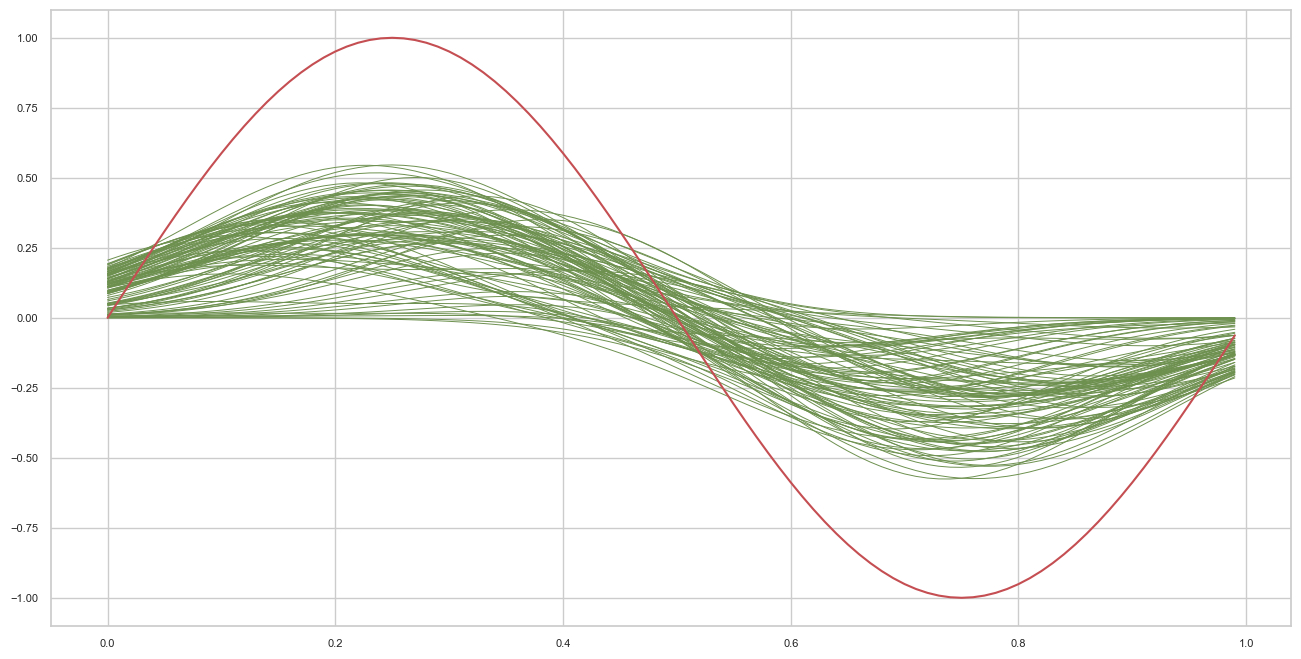

In [11]:
# per ogni traning set, apprendimento della funzione e plot sui valori di x_plot
f = plt.figure(figsize=(16,8))
for x in training_sets:
    # calcola valori target corrispondenti a valori in x_plot
    t=np.sin(2*np.pi*x)
    # istanzia il modello sul training set
    model.fit(Phi(x),t)
    # predice in corrispondenza ai valori in x_plot 
    y = model.predict(Phi(x_plot))
    # effettua il plot dei valori predetti
    sns.lineplot(x=np.ravel(x_plot), y=np.ravel(y), color=colors[3], linewidth=0.7, alpha=1)
# plot della funzione originaria
sns.lineplot(x=np.ravel(x_plot), y=np.ravel(np.sin(np.pi*2*x_plot).reshape(-1,1)), color='r', linewidth=1.5)
plt.show()

## Il percorso dei coefficienti

Nella seconda parte costruiamo un singolo training set di $25$ punti (ancora senza rumore) e calcoliamo la matrice di design.

In [12]:
# costruzione training set
X = np.random.uniform(0.0, 1.0, 25).reshape(-1,1)
t = np.sin(2*np.pi*X).ravel()

# applicazione funzioni base
phi = Phi(X)

Controlliamo le dimensioni: $25$ elementi con una feature, e una matrice di design $25\times24$.

In [13]:
X.shape

(25, 1)

In [14]:
phi.shape

(25, 24)

Consideriamo $200$ valori di $\lambda$ distribuiti uniformemente su scala logaritmica tra $10^{-14}$ e $10^{-1}$.

In [15]:
# insieme di valori del coefficiente di regolazione considerati
n_alphas = 200
alphas = np.logspace(-14, -1, n_alphas)

Questa volta il modello `Ridge` è creato con le impostazioni predefinite, quindi con `fit_intercept=True`: viene stimato anche un termine costante, che non è penalizzato e non compare in `coef_`.

In [16]:
# crea modello
clf = Ridge()

Per ogni valore di $\lambda$ stimiamo il modello e conserviamo il vettore dei $24$ coefficienti.

In [17]:
# lista dei coefficienti appresi per i vari alpha
coefs = []

# per ogni alpha, istanzia il modello, apprende i coefficienti e li salva
for a in alphas:
    clf.set_params(alpha=a)
    clf.fit(phi, t)
    coefs.append(clf.coef_)

In [18]:
np.array(coefs).shape

(200, 24)

## Lettura del grafico

Il grafico riporta i $24$ coefficienti in funzione di $\lambda$, con l'asse orizzontale invertito: da sinistra a destra la regolarizzazione **diminuisce**.

- Per $\lambda$ grande (a sinistra) tutti i coefficienti sono vicini a zero: il termine di penalità domina la funzione obiettivo e il modello è quasi costante.
- Al diminuire di $\lambda$ i coefficienti crescono e si differenziano, man mano che il termine dei dati prende il sopravvento.
- Per $\lambda$ molto piccolo (a destra) i coefficienti possono assumere valori **molto grandi**, positivi e negativi, che si compensano a vicenda: è il segno tipico dell'overfitting, in cui il modello usa grandi oscillazioni delle singole funzioni base per passare esattamente per i punti. Con $24$ funzioni base gaussiane strette e molto sovrapposte, le colonne di $\boldsymbol\Phi$ sono fortemente correlate e la matrice $\boldsymbol\Phi^T\boldsymbol\Phi$ è mal condizionata: senza regolarizzazione la soluzione diventa instabile.

Si noti che la ridge regression **riduce** i coefficienti ma non li rende esattamente nulli: tutti restano diversi da zero per ogni $\lambda$. Con la Lasso (`sklearn.linear_model.Lasso`), invece, al crescere di $\lambda$ i coefficienti si annullano uno dopo l'altro, come spiegato geometricamente nelle note: è un utile esercizio ripetere il grafico con `Lasso` al posto di `Ridge`.

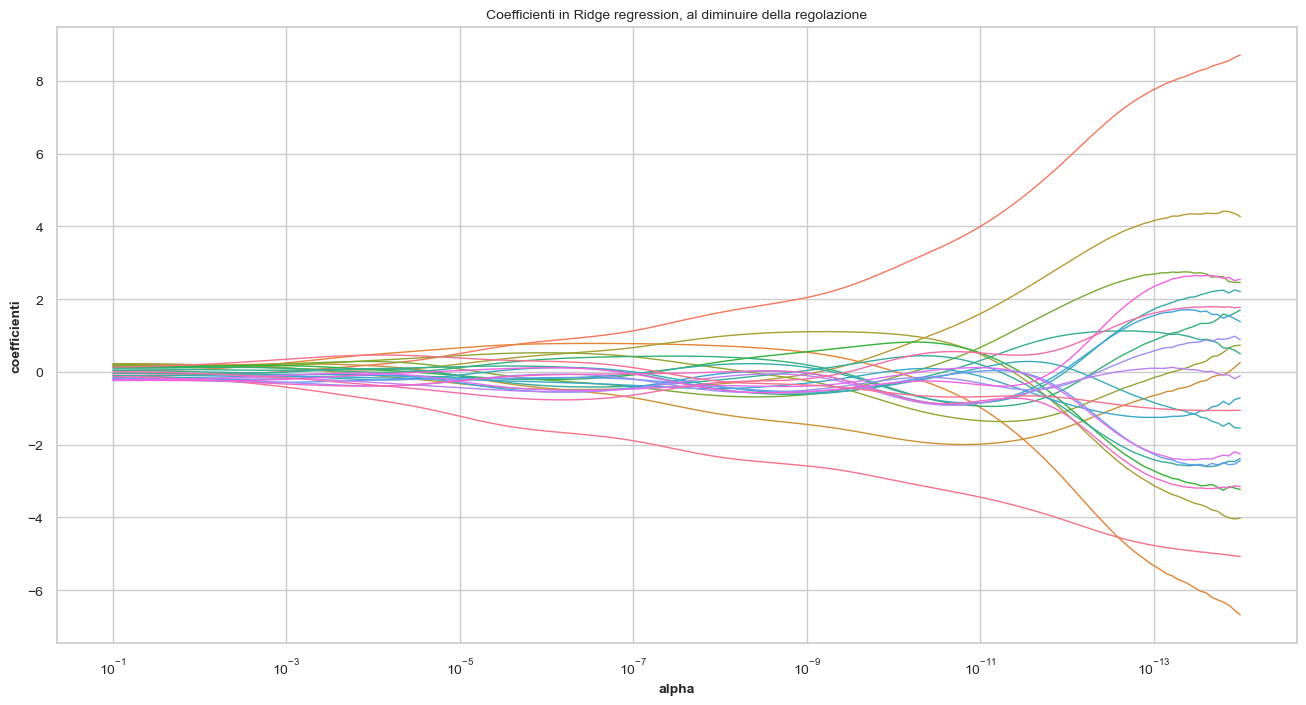

In [18]:
fig = plt.figure(figsize=(16,8))
fig.patch.set_facecolor('white')
ax = fig.gca()
import pandas as pd
# formato "lungo": una riga per ogni coppia (alpha, coefficiente), adatto a seaborn
coefs_df = (pd.DataFrame(np.asarray(coefs), index=alphas).rename_axis('alpha').reset_index()
            .melt(id_vars='alpha', var_name='coefficiente', value_name='valore'))
sns.lineplot(data=coefs_df, x='alpha', y='valore', hue='coefficiente', palette='husl',
             linewidth=1, legend=False, ax=ax)
ax.set_xscale('log')
# inversione dell'asse x, da valori più grandi a valori più piccoli
ax.set_xlim(ax.get_xlim()[::-1])
plt.xlabel('alpha', fontsize=10)
plt.ylabel('coefficienti', fontsize=10)
plt.title('Coefficienti in Ridge regression, al diminuire della regolazione', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()